# Etapa 6. Filtrado probabilístico (Bloom Filter y Count-Min Sketch)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de la etapa 6: Aris.

## Función de la etapa en el pipeline

El escenario B pide **reconocer medios de pago, dispositivos o cuentas señaladas y estimar la intensidad de intentos dentro de una ventana temporal, verificando las alertas antes de bloquear operaciones**. La etapa 6 recibe los eventos en el orden de servicio de la etapa 2 y revisa cada compra y cada alerta de pago con dos estructuras probabilísticas implementadas a mano.

| Pregunta | Estructura | Respuesta | Error posible |
| --- | --- | --- | --- |
| ¿Esta cuenta, tarjeta o dispositivo está señalado? | **Bloom Filter** (Bloom, 1970) | "posiblemente sí" o "seguro que no" | Falsos positivos, nunca falsos negativos |
| ¿Cuántos intentos de pago hizo esta tarjeta en la ventana? | **Count-Min Sketch** (Cormode y Muthukrishnan, 2005) | Una estimación f̂ ≥ f | Sobreestima a lo más ε·N con probabilidad 1 − δ |

Como las dos estructuras pueden equivocarse por exceso, **toda alerta se verifica con una estructura exacta antes de actuar**. El positivo del Bloom Filter se confirma en la lista exacta (la `TablaHash` de la etapa 3) y la ráfaga del CMS se confirma con el conteo exacto de las órdenes de la ventana. La estructura exacta solo se consulta para los pocos eventos que el filtro probabilístico marca.

**Salidas para las etapas siguientes.** `etapa6_ordenes_bloqueadas.json` (la etapa 8 excluye esas órdenes del grafo de co-compra) y `etapa6_alertas.jsonl` (la etapa 9 las muestra en el panel de alertas).

**Cómo se ejecuta.** El recorrido de los 9.9 millones de eventos lo hace `scripts/etapa6_detectar.py` en segundo plano, en alrededor de 1 minuto, y deja sus resultados en `data/interim/<CATEGORIA>/`. Este notebook muestra las estructuras, hace una demostración en vivo con los primeros eventos del stream y analiza los resultados de la corrida completa. Los experimentos de escalabilidad de 1K a 10M están en `notebooks/etapa6_experimentos.ipynb`.

## Paso 1. Configuración y entrada

| Archivo | Origen | Uso |
| --- | --- | --- |
| `etapa2_eventos.jsonl` | Etapa 2 | Stream de eventos limpios en orden de servicio, leído línea por línea |
| `listas_senalados.json` | Etapa 0 (generador) | 30 cuentas, 200 tarjetas y 50 dispositivos señalados, que se insertan en el Bloom Filter |
| `etapa0_inyecciones.json` | Etapa 0 (generador) | Verdad de referencia con las ráfagas y compras fraudulentas inyectadas |

In [1]:
import json
import platform
import sys
import time
from collections import Counter
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.stage3_storage import RUTA_EVENTOS_ETAPA2, leer_eventos
from src.stage6_probabilistic import (EPSILON, DELTA, N_VENTANAS, P_FP, RUTA_ALERTAS, RUTA_BLOQUEADAS, UMBRAL,
                                      VENTANA_S, BloomFilter, CountMinSketch, DetectorFraude, cargar_listas)

CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS
RUTA_METRICAS = CARPETA_INTERIM / "etapa6_metricas.json"
RUTA_COMPRAS = CARPETA_INTERIM / "etapa6_compras.npz"

listas = cargar_listas()
inyecciones = json.loads((CARPETA_INTERIM / "etapa0_inyecciones.json").read_text(encoding="utf-8"))
print(f"Categoría: {config.CATEGORIA}   semilla: {config.SEED}")
print({k: len(v) for k, v in listas.items()})
print("Fraude inyectado por la etapa 0:",
      {k: inyecciones[k] for k in ["rafagas_fraude", "compras_fraudulentas", "tipo_payment_alert", "alertas_legitimas"]})

Categoría: Office_Products   semilla: 42
{'cuentas': 30, 'tarjetas': 200, 'dispositivos': 50}
Fraude inyectado por la etapa 0: {'rafagas_fraude': 2970, 'compras_fraudulentas': 37095, 'tipo_payment_alert': 15184, 'alertas_legitimas': 3958}


## Paso 2. Bloom Filter

Un Bloom Filter es un arreglo de **m bits** y **k funciones hash**. Insertar una clave enciende sus k bits; consultar revisa si los k están encendidos. Si alguno está apagado, la clave **seguro** no se insertó. Si todos están encendidos, **posiblemente** se insertó, porque otros elementos pudieron encender esos bits (falso positivo).

Con n claves y una tasa objetivo p, los valores óptimos son

$$m = -\frac{n \ln p}{(\ln 2)^2}, \qquad k = \frac{m}{n}\ln 2, \qquad p_{FP} \approx \left(1 - e^{-kn/m}\right)^k$$

Las k posiciones se obtienen por **doble hashing**, g_i(x) = h1(x) + i·h2(x) mod m (Kirsch y Mitzenmacher, 2006), con h1 y h2 tomados de un único BLAKE2b de 128 bits. Así se calcula un solo hash por clave, y es determinista entre ejecuciones, a diferencia del `hash()` de Python. Cada clave lleva su tipo como prefijo (`tarjeta:pay_…`) para que una cuenta y una tarjeta con el mismo texto no se confundan.

In [2]:
claves = ([f"cuenta:{c}" for c in listas["cuentas"]] + [f"tarjeta:{t}" for t in listas["tarjetas"]]
          + [f"dispositivo:{d}" for d in listas["dispositivos"]])
bloom = BloomFilter.para(len(claves), P_FP)
for c in claves:
    bloom.agregar(c)

print(f"n = {len(claves)} claves, p objetivo = {P_FP}")
print(f"m = {bloom.m:,} bits ({bloom.memoria_bytes} bytes), k = {bloom.k} funciones hash, "
      f"{bloom.bits_encendidos() / bloom.m:.1%} de bits encendidos")
print(f"Tasa de falsos positivos teórica: {bloom.tasa_fp_teorica():.4f}")

tarjeta = "tarjeta:" + listas["tarjetas"][0]
print(f"\n¿{tarjeta} está señalada?  {tarjeta in bloom}")
print(f"Posiciones de sus {bloom.k} bits: {bloom._posiciones(tarjeta)}")
ausentes = [f"tarjeta:pay_{i:08x}" for i in range(100_000)]
fp = sum(c in bloom for c in ausentes)
print(f"De 100 000 tarjetas no señaladas, {fp:,} dan positivo ({fp / len(ausentes):.4f}): son falsos positivos")

n = 280 claves, p objetivo = 0.01
m = 2,684 bits (336 bytes), k = 7 funciones hash, 52.2% de bits encendidos
Tasa de falsos positivos teórica: 0.0100

¿tarjeta:pay_749176f4 está señalada?  True
Posiciones de sus 7 bits: [1176, 1923, 2670, 733, 1480, 2227, 290]
De 100 000 tarjetas no señaladas, 1,104 dan positivo (0.0110): son falsos positivos


## Paso 3. Count-Min Sketch por ventanas

El CMS es una matriz de **d filas × w contadores**. Cada fila tiene su propia función hash. Agregar una clave suma 1 en un contador de cada fila; estimar devuelve el **mínimo** de esos d contadores. Como varias claves pueden caer en el mismo contador, cada contador es mayor o igual que la frecuencia real, y por eso **el CMS nunca subestima**. Con

$$w = \left\lceil \frac{e}{\varepsilon} \right\rceil, \qquad d = \left\lceil \ln \frac{1}{\delta} \right\rceil$$

la estimación cumple f ≤ f̂ ≤ f + ε·N con probabilidad 1 − δ, donde N es el total de la ventana. La memoria es w·d contadores, **independiente del número de claves distintas**.

El enunciado pide definir la clave, la ventana y el umbral.

| Parámetro | Valor | Justificación |
| --- | --- | --- |
| Clave | `payment_id` de cada **intento de pago** (una orden) | Una orden con 4 productos genera un solo pago. Contar productos retenía compras legítimas de varias unidades |
| Ventana | Fijas de 5 min; la estimación suma la ventana actual y la anterior | Una ráfaga del generador son 5 a 20 compras separadas por 5 a 40 s (de 25 s a 13 min). Sumar dos ventanas evita que una ráfaga quede partida en el borde |
| Umbral | 5 intentos en la ventana | Mínimo tamaño de una ráfaga inyectada; el Paso 6 lo justifica con los datos |
| ε, δ | 0.01 y 0.01 → w = 272, d = 5 | En una ventana hay decenas de órdenes, así que ε·N < 1 y el CMS es casi exacto con 11 KB por ventana |
| Ventanas retenidas | 288 (24 h) en un arreglo circular | La etapa 2 entrega en orden de prioridad y no de ts. Durante el incidente de la etapa 2 hay eventos que se atienden horas después |

In [3]:
cms = CountMinSketch.para(EPSILON, DELTA)
print(f"ε = {EPSILON}, δ = {DELTA}  ->  w = {cms.w}, d = {cms.d}, {cms.memoria_bytes / 1024:.1f} KB por ventana")
print(f"Ventanas de {VENTANA_S // 60} min, {N_VENTANAS} retenidas: {N_VENTANAS * cms.memoria_bytes / 1e6:.1f} MB en total")

# Ejemplo: una tarjeta con 7 intentos entre 2 000 tarjetas con 1 intento cada una
for i in range(2_000):
    cms.agregar(f"pay_{i:08x}")
for _ in range(7):
    cms.agregar("pay_rafaga")
print(f"\nEstimación de pay_rafaga: {cms.estimar('pay_rafaga')} (real 7)")
estimaciones = [cms.estimar(f"pay_{i:08x}") for i in range(2_000)]
print(f"Tarjetas con 1 intento: estimación media {np.mean(estimaciones):.3f}, máxima {max(estimaciones)} "
      f"(cota ε·N = {cms.epsilon * cms.total:.1f})")

ε = 0.01, δ = 0.01  ->  w = 272, d = 5, 10.6 KB por ventana
Ventanas de 5 min, 288 retenidas: 3.1 MB en total

Estimación de pay_rafaga: 11 (real 7)
Tarjetas con 1 intento: estimación media 5.391, máxima 12 (cota ε·N = 20.1)


## Paso 4. Demostración en vivo con los primeros eventos del stream

El `DetectorFraude` combina las dos estructuras. Para cada compra o alerta de pago:

1. Consulta la cuenta, la tarjeta y el dispositivo en el Bloom Filter. Un positivo se confirma en la lista exacta; si se confirma, la operación se **bloquea**. Si no, es un falso positivo del filtro y no tiene efecto.
2. Si es una compra, suma el intento de pago al CMS de su ventana. Si la estimación llega al umbral, cuenta exactamente las órdenes de esa tarjeta en la ventana. Si el conteo exacto también llega al umbral, la orden queda **retenida para revisión**. Una ráfaga sin clave señalada indica un patrón sospechoso, pero no basta para probar el fraude.

Aquí se procesan los primeros 300 000 eventos de la salida de la etapa 2.

In [4]:
detector = DetectorFraude(listas)
alertas = []
t0 = time.perf_counter()
for e in islice(leer_eventos(RUTA_EVENTOS_ETAPA2), 300_000):
    alerta = detector.procesar(e)
    if alerta is not None:
        alertas.append(alerta)
duracion = time.perf_counter() - t0

print(f"300 000 eventos en {duracion:.1f} s; {detector.metricas['revisados']:,} compras y alertas de pago revisadas")
print(dict(detector.metricas))
pd.DataFrame(alertas)[["event_type", "user_id", "payment_id", "motivos", "estimado_cms", "conteo_exacto",
                       "decision"]].drop_duplicates("payment_id").head(10)

300 000 eventos en 1.7 s; 62,614 compras y alertas de pago revisadas
{'revisados': 62614, 'bloom_consultas': 187842, 'bloom_positivos': 6178, 'bloom_falsos_positivos': 2059, 'intentos': 42219, 'alertas': 1440, 'bloquear': 1373, 'alertas_cuenta': 1373, 'cms_alertas': 776, 'alertas_rafaga': 776, 'revisar': 67}


,event_type,user_id,payment_id,motivos,estimado_cms,conteo_exacto,decision
0,purchase,APOFB6P2MCUBESJ7DYTZHQOO37JT,pay_b1aa0f6a,[cuenta],1.0,NaN,bloquear
10,payment_alert,ARNGLYUYGR5OWD7THFRRC75OD2PW,pay_1986b4b2,[cuenta],NaN,NaN,bloquear
28,purchase,AK4WIA6CXPYWUPZCHWJSPQNXKWII,pay_fb140bc3,[cuenta],1.0,NaN,bloquear
49,purchase,AE4PQHBWG6HFLMH7ABL5NLWND5UA,pay_771f406e,[rafaga],5.0,5.0,revisar
51,purchase,AEVBRR5DORGEPBVHN6HNTN3CLVRA,pay_5a2e3971,[rafaga],5.0,5.0,revisar
55,payment_alert,AR6D7F6IDNXKTQMSIWA5RXXVLCVK,pay_e32f2e63,[cuenta],NaN,NaN,bloquear
75,purchase,ANXRTHHNAKVMFOETAMSAUEOBMGKY,pay_1327f1bc,[cuenta],1.0,NaN,bloquear
83,purchase,APCYYEPRI3NGRXGJ7UOQDHKSHHCU,pay_f6478986,[cuenta],1.0,NaN,bloquear
91,payment_alert,AICJIKREHWWCNRNGN4SW3YMALY36,pay_dbfdd97e,[cuenta],NaN,NaN,bloquear
98,payment_alert,A26DAJV6MWCWUDY3TD7ZLNLQK32D,pay_bea4ff31,[cuenta],NaN,NaN,bloquear


## Paso 5. Resultados sobre el stream completo

Resultados de `scripts/etapa6_detectar.py` sobre los 9 940 617 eventos de la etapa 2. Para evaluar se usa la verdad de referencia del generador, según la cual un evento es fraude si su cuenta pertenece a la lista de cuentas fraudulentas. El detector no consulta esa información.

In [5]:
metricas = json.loads(RUTA_METRICAS.read_text(encoding="utf-8"))
d, ev = metricas["detector"], metricas["evaluacion"]
print(f"Eventos: {metricas['eventos']:,}   compras y alertas revisadas: {d['revisados']:,}   "
      f"intentos de pago: {d['intentos']:,}")
print(f"Tiempo del detector: {metricas['tiempo_detector_s']:.0f} s "
      f"({metricas['us_por_evento_revisado']:.1f} µs por evento revisado)")

decisiones = pd.DataFrame({
    "fraude real": [ev.get("bloquear_fraude", 0), ev.get("revisar_fraude", 0), ev.get("aprobar_fraude", 0)],
    "legítimo": [ev.get("bloquear_legitimo", 0), ev.get("revisar_legitimo", 0), ev.get("aprobar_legitimo", 0)],
}, index=["bloquear", "revisar", "aprobar"])
display(decisiones)
print(f"Bloqueos: precisión {metricas['precision_bloqueos']:.4f}, recall {metricas['recall_bloqueos']:.4f}")
print(f"Todas las alertas (bloquear + revisar): precisión {metricas['precision_alertas']:.4f}, "
      f"recall {metricas['recall_alertas']:.4f}")
print(f"Órdenes bloqueadas para la etapa 8: {metricas['ordenes_bloqueadas']:,}")

Eventos: 9,940,617   compras y alertas revisadas: 1,993,954   intentos de pago: 1,336,626
Tiempo del detector: 19 s (9.7 µs por evento revisado)


,fraude real,legítimo
bloquear,47766,0
revisar,0,2931
aprobar,0,1943257


Bloqueos: precisión 1.0000, recall 1.0000
Todas las alertas (bloquear + revisar): precisión 0.9422, recall 1.0000
Órdenes bloqueadas para la etapa 8: 36,803


### Bloom Filter en el stream real

Cada evento revisado consulta hasta tres claves. Los positivos que la lista exacta no confirma son falsos positivos del filtro. La tasa medida se compara con la teórica.

In [6]:
positivos_reales = d["bloom_positivos"] - d["bloom_falsos_positivos"]
negativos = d["bloom_consultas"] - positivos_reales if "bloom_consultas" in d else 3 * d["revisados"] - positivos_reales
print(f"Consultas al Bloom Filter: {negativos + positivos_reales:,}")
print(f"Positivos confirmados por la lista exacta: {positivos_reales:,}")
print(f"Falsos positivos (descartados por la verificación): {d['bloom_falsos_positivos']:,} "
      f"-> tasa {d['bloom_falsos_positivos'] / negativos:.4f} (teórica {metricas['bloom']['tasa_fp_teorica']:.4f})")
print(f"Sin la verificación exacta, cada uno de esos {d['bloom_falsos_positivos']:,} positivos habría bloqueado una operación legítima.")
print(f"Memoria: Bloom Filter {metricas['memoria_bloom_bytes']} bytes "
      f"(m = {metricas['bloom']['m']:,} bits, k = {metricas['bloom']['k']})")

Consultas al Bloom Filter: 5,981,862
Positivos confirmados por la lista exacta: 143,298
Falsos positivos (descartados por la verificación): 62,970 -> tasa 0.0108 (teórica 0.0100)
Sin la verificación exacta, cada uno de esos 62,970 positivos habría bloqueado una operación legítima.
Memoria: Bloom Filter 336 bytes (m = 2,684 bits, k = 7)


### Count-Min Sketch frente al conteo exacto en el stream real

Para cada compra se guardó la estimación del CMS y el conteo exacto de órdenes de su tarjeta en las mismas dos ventanas (un diccionario `(tarjeta, ventana) -> órdenes` usado solo como línea base).

In [7]:
compras = np.load(RUTA_COMPRAS)
estimado, conteo, fraude = compras["estimado"], compras["conteo"], compras["fraude"]
error = estimado.astype(np.int64) - conteo
print(f"Compras: {len(error):,}   subestimaciones: {(error < 0).sum()}   con error > 0: {(error > 0).sum():,} "
      f"({(error > 0).mean():.4%})   error máximo: {error.max()}")
print(f"Eventos descartados por llegar más de 24 h tarde: {metricas['cms_descartados_por_tardios']:,}")
pares = metricas["pares_tarjeta_ventana_exactos"]
print(f"Memoria: CMS {metricas['memoria_cms_bytes'] / 1e6:.1f} MB fijos (288 ventanas) frente a "
      f"{pares:,} pares (tarjeta, ventana) en el diccionario exacto")

Compras: 1,978,936   subestimaciones: 0   con error > 0: 2,807 (0.1418%)   error máximo: 15
Eventos descartados por llegar más de 24 h tarde: 0
Memoria: CMS 3.1 MB fijos (288 ventanas) frente a 1,260,275 pares (tarjeta, ventana) en el diccionario exacto


## Paso 6. Elección del umbral

La regla de ráfaga se evalúa sola, sin la lista de señalados, para cada umbral posible. Así se mide qué aportaría el CMS frente a un atacante cuya tarjeta todavía no está en la lista. Una compra cuenta como alerta si el conteo de órdenes de su tarjeta en la ventana llega al umbral.

,alertas,fraude detectado,legítimas retenidas,precisión,recall
umbral,,,,,
2,159124,33690,125434,0.212,0.919
3,54125,30722,23403,0.568,0.838
4,35057,27752,7305,0.792,0.757
5,27683,24780,2903,0.895,0.676
6,23301,21817,1484,0.936,0.595
7,19916,19044,872,0.956,0.519
8,17042,16460,582,0.966,0.449
9,14442,14053,389,0.973,0.383
10,12115,11850,265,0.978,0.323


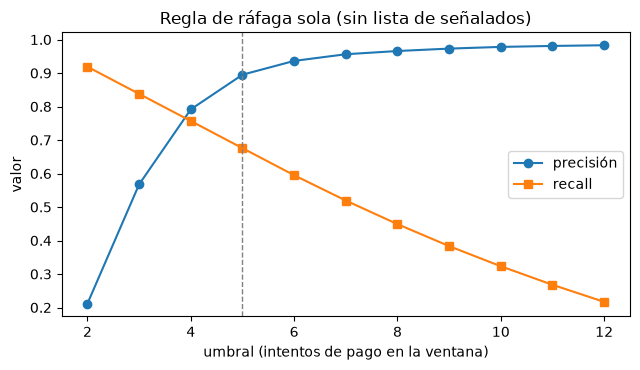

In [8]:
filas = []
for u in range(2, 13):
    alerta = conteo >= u
    vp, fp_ = int((alerta & fraude).sum()), int((alerta & ~fraude).sum())
    filas.append({"umbral": u, "alertas": int(alerta.sum()), "fraude detectado": vp, "legítimas retenidas": fp_,
                  "precisión": vp / max(1, vp + fp_), "recall": vp / max(1, fraude.sum())})
umbrales = pd.DataFrame(filas).set_index("umbral")
display(umbrales.style.format({"precisión": "{:.3f}", "recall": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(umbrales.index, umbrales["precisión"], marker="o", label="precisión")
ax.plot(umbrales.index, umbrales["recall"], marker="s", label="recall")
ax.axvline(UMBRAL, color="gray", ls="--", lw=1)
ax.set_xlabel("umbral (intentos de pago en la ventana)")
ax.set_ylabel("valor")
ax.set_title("Regla de ráfaga sola (sin lista de señalados)")
ax.legend()
fig.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa6_umbral.png", dpi=150)
plt.show()

## Paso 7. Salida de la etapa 6

| Archivo | Contenido | Lo usa |
| --- | --- | --- |
| `etapa6_alertas.jsonl` | Una línea por operación con alerta: motivos, estimación del CMS, conteo exacto y decisión | Etapa 9 (panel de alertas) |
| `etapa6_ordenes_bloqueadas.json` | `order_id` de las operaciones bloqueadas | Etapa 8 (se excluyen del grafo de co-compra) |
| `etapa6_metricas.json` | Conteos, tiempos, memoria y evaluación | Informe |

In [9]:
bloqueadas = json.loads(RUTA_BLOQUEADAS.read_text(encoding="utf-8"))
n_alertas = sum(1 for _ in open(RUTA_ALERTAS, encoding="utf-8"))
print(f"{RUTA_ALERTAS.name}: {n_alertas:,} alertas ({RUTA_ALERTAS.stat().st_size / 1e6:.1f} MB)")
print(f"{RUTA_BLOQUEADAS.name}: {len(bloqueadas):,} órdenes bloqueadas")
with open(RUTA_ALERTAS, encoding="utf-8") as f:
    ejemplo = [json.loads(linea) for linea in islice(f, 3)]
pd.DataFrame(ejemplo)

etapa6_alertas.jsonl: 50,697 alertas (18.9 MB)
etapa6_ordenes_bloqueadas.json: 36,803 órdenes bloqueadas


,event_id,event_type,ts,user_id,order_id,payment_id,device_id,motivos,clave_senalada,estimado_cms,conteo_exacto,decision,fraude_real
0,e000001899,purchase,1.656702e+09,APOFB6P2MCUBESJ7DYTZHQOO37JT,o00000292,pay_b1aa0f6a,dev_1712fb16,[cuenta],cuenta:APOFB6P2MCUBESJ7DYTZHQOO37JT,1.0,None,bloquear,True
1,e000001904,payment_alert,1.656702e+09,APOFB6P2MCUBESJ7DYTZHQOO37JT,o00000296,pay_b1aa0f6a,dev_1712fb16,[cuenta],cuenta:APOFB6P2MCUBESJ7DYTZHQOO37JT,NaN,None,bloquear,True
2,e000001902,purchase,1.656702e+09,APOFB6P2MCUBESJ7DYTZHQOO37JT,o00000295,pay_b1aa0f6a,dev_1712fb16,[cuenta],cuenta:APOFB6P2MCUBESJ7DYTZHQOO37JT,2.0,None,bloquear,True
